In [60]:
%pip install pandas
import pandas as pd
import boto3
import json
import gzip
from datetime import datetime
from io import StringIO, BytesIO
#import matplotlib.pyplot as plt
import requests

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
s3_client = boto3.client("s3")

bucket = "s3-3601-final-project"
prefix = "ncdot/traffic/"
file_path = "s3://s3-3601-final-project/ncdot/traffic/aadt_stations.json.gz"

response = s3_client.list_objects_v2(Bucket=bucket, Prefix=prefix)

data_list = []

for obj in response.get("Contents", []):
        file_key = obj["Key"]

        if not file_key.endswith(".json.gz"):
            continue

        response = s3_client.get_object(
            Bucket=bucket,
            Key=file_key
        )

        compressed_content = response["Body"].read()

        with gzip.GzipFile(fileobj=BytesIO(compressed_content)) as gzip_file:

            raw_json_data = json.loads(gzip_file.read().decode("utf-8"))

        temp_df = pd.json_normalize(raw_json_data, record_path="features")

        temp_df.columns = [col.replace("attributes.", "")
            for col in temp_df.columns
        ]

        # Save the timestamp from the filename
        temp_df["source_file"] = file_key

        data_list.append(temp_df)

df = pd.concat(data_list, ignore_index=True)
print(df.head())
if not df.empty and "timestamp" in df.columns:
    df["timestamp"] = pd.to_datetime(
        df["timestamp"], format="%Y-%m-%d_%H-%M-%S"
    )
    df["day_of_week"] = df["timestamp"].dt.day_name()

NoSuchKey: An error occurred (NoSuchKey) when calling the GetObject operation: The specified key does not exist.

In [52]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   LocationID   20 non-null     object 
 1   COUNTY       20 non-null     object 
 2   ROUTE        20 non-null     object 
 3   LOCATION     20 non-null     object 
 4   AADT_2022    20 non-null     object 
 5   geometry.x   20 non-null     float64
 6   geometry.y   20 non-null     float64
 7   source_file  20 non-null     object 
dtypes: float64(2), object(6)
memory usage: 1.4+ KB


In [40]:
url = "https://services.arcgis.com/NuWFvHYDMVmmxMeM/ArcGIS/rest/services/NCDOT_AADT_Stations/FeatureServer/0/query"


location_ids = [
   "0600000063",
   "0600000145",
   "0600000829",
   "0600000107",
   "0600000108",
   "0600000414", 
   "0600000412",
   "0600000044",
   "0600000065",
   "0600001182",
 
]

where = "LocationID IN ({})".format(
    ",".join(f"'{x}'" for x in location_ids)
)

params = {
    "where": where,
    "outFields": "LocationID,COUNTY,ROUTE,LOCATION,AADT_2022",
    "returnGeometry": "true",
    "outSR": "4326",
    "f": "json",
}

response = requests.get(url, params=params)
data = response.json()

df = pd.json_normalize(data["features"])

df = df.rename(columns={
    "geometry.x": "longitude",
    "geometry.y": "latitude"
})

df.head(10)

df = df.rename(columns={
    "geometry.x": "longitude",
    "geometry.y": "latitude"
})

df.head(10)



,attributes.LocationID,attributes.COUNTY,attributes.ROUTE,attributes.LOCATION,attributes.AADT_2022,longitude,latitude
0,0600000044,MECKLENBURG,US 29/NC 49,EAST OF STETSON DR,29500,-80.759574,35.287985
1,0600000063,MECKLENBURG,NC 49,WEST OF I-485,32500,-80.711385,35.311292
2,0600000065,MECKLENBURG,US 29,SOUTH OF UNIVERSITY POINTE BLVD,18000,-80.755360,35.294440
3,0600000107,MECKLENBURG,NC 49,EAST OF SUTHER RD,26500,-80.727801,35.303270
4,0600000108,MECKLENBURG,NC 49,WEST OF SUTHER RD,27500,-80.729977,35.301876
5,0600000145,MECKLENBURG,NC 49,EAST OF SR 5394 MALLARD CK CH RD,42000,-80.717633,35.309346
6,0600000412,MECKLENBURG,NC 24 (WT HARRIS BLVD),SOUTH OF US 29,47500,-80.748333,35.304176
7,0600000414,MECKLENBURG,NC 24 (E WT HARRIS BLVD),EAST OF SR 5316,51500,-80.739913,35.293191
8,0600000829,MECKLENBURG,NC 49,EAST OF SR 2939,32500,-80.722975,35.306539
9,0600001182,MECKLENBURG,SR 2833,NORTH OF NC 49,15500,-80.724601,35.306768


In [42]:
#converting into a csv to save into our shared s3 bucket
df.to_csv("traffic_counts.csv", index=False)


s3_client.upload_file(
    "traffic_counts.csv",
    "s3-3601-final-project",
    "ncdot/traffic/traffic_counts.csv"
)

In [54]:
df.isnull().sum()

attributes.LocationID    0
attributes.COUNTY        0
attributes.ROUTE         0
attributes.LOCATION      0
attributes.AADT_2022     0
longitude                0
latitude                 0
dtype: int64

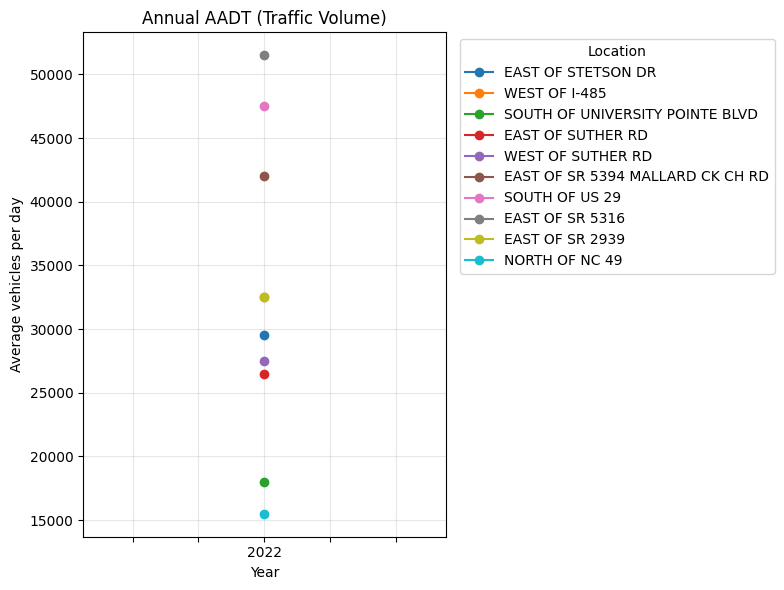

In [55]:
year_cols = [f"attributes.AADT_2022"]
aadt = df[year_cols].apply(pd.to_numeric, errors="coerce")
aadt.columns = [col.rsplit("_", 1)[1] for col in year_cols]
aadt.index = df["attributes.LOCATION"]

ax = aadt.T.plot(marker="o", figsize=(8, 6))
ax.set(
    title="Annual AADT (Traffic Volume)",
    xlabel="Year",
    ylabel="Average vehicles per day",
)
ax.legend(title="Location", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()